# 2.1 — Univariate Signal: coverage & IV ranking

**Goal of this notebook**: rank each variable's standalone power to separate goods from bads
(IV), paired with its coverage (the practicality dimension), and freeze the candidate shortlist
(`VAR_SELECTION`) for the rest of Phase 2.

**Input**: `data/interim/applications.parquet` (validated in 1.1) **and the tuned binning in
`references/bin_spec.yaml`** (estimated & hand-merged in notebook **2.0 — binning workbench**,
which is a prerequisite of this one). Analysis runs on the labeled `Contratado` sample — the
**selection-bias caveat applies to every number here**.

**What moved out**: the WoE/IV machinery now lives in the reusable module
`src/credit_policy/` (`woe.py`, `binning.py`); the per-bin WoE table, the WoE *shape* profiles
and the WoE-over-SAFRA stability plots moved to notebook 2.0, where they drive the manual bin
merging. This notebook consumes the resulting bins rather than estimating its own.

**Conventions (unchanged)**:
- **Bins from the spec** — numerics: cut-point bins; categoricals: grouped categories; both with
  an explicit `(missing)` bin (NaN = "no snapshot" / "no open-finance consent", a candidate
  signal in itself, so IV includes it). Sentinels never reach here (1.1 sent them to NaN).
- **Flags** — `has_snapshot`, `has_open_finance` binned inline as yes/no: they isolate the pure
  "is data availability predictive?" question.
- **WoE** — `WoE = ln(%goods/%bads)`, **positive = safer**; 0.5 additive smoothing (no `ln(0)`).

*(to continue in Phase 2: PSI / population stability & IV-per-vintage, redundancy/correlation
between candidates, leakage screen, weighting sensitivity — see analysis-plan.md Fase 2.)*

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))
from credit_policy import woe, binning, VAR_SELECTION, save_fig   # noqa: E402  (path set above)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

APP_PATH = PROJECT_DIR / "data" / "interim" / "applications.parquet"
BIN_SPEC_PATH = PROJECT_DIR / "references" / "bin_spec.yaml"
FIG_DIR = PROJECT_DIR / "reports" / "figures"  # deck figures land here

COLOR_POS, COLOR_NEG, COLOR_MISS = "steelblue", "indianred", "0.55"
FLAG_SPEC = {"type": "categorical", "groups": {"yes": ["yes"], "no": ["no"]}}

## 1. Load & labeled sample

All signal measurement uses the `Contratado` subset (the only rows with `OVER30M2`).

In [2]:
app = pd.read_parquet(APP_PATH)
lab = app[app["OVER30M2"].notna()].copy()
y = lab["OVER30M2"].astype(int)

spec = binning.load_spec(BIN_SPEC_PATH)          # tuned in notebook 2.0
NUM_VARS = ["score_klavi_1", "score_klavi_2", "Renda", "Capacidade Financeira"]
CAT_VARS = ["classe_social", "status_empregaticio", "regiao", "risco_aposta"]
FLAG_VARS = ["has_snapshot", "has_open_finance"]
ALL_VARS = NUM_VARS + CAT_VARS + FLAG_VARS
assert set(spec) == set(NUM_VARS + CAT_VARS), "bin_spec.yaml must cover all candidate variables"

print(f"labeled sample: {len(lab):,} applications  |  bads: {y.sum():,}  |  default rate: {y.mean():.2%}")
print(f"safras: {lab['SAFRA'].min()}–{lab['SAFRA'].max()}  |  labeled rows per safra: "
      f"{lab.groupby('SAFRA').size().min():,}–{lab.groupby('SAFRA').size().max():,}")
coverage = pd.DataFrame({
    "n_nonmiss": lab[ALL_VARS].notna().sum(),
    "coverage_pct": (lab[ALL_VARS].notna().mean() * 100).round(1),
})
coverage

labeled sample: 24,148 applications  |  bads: 2,488  |  default rate: 10.30%
safras: 202406–202506  |  labeled rows per safra: 1,417–2,367


,n_nonmiss,coverage_pct
score_klavi_1,981,4.1
score_klavi_2,11089,45.9
Renda,1081,4.5
Capacidade Financeira,11008,45.6
classe_social,12442,51.5
status_empregaticio,12318,51.0
regiao,12415,51.4
risco_aposta,1081,4.5
has_snapshot,24148,100.0
has_open_finance,24148,100.0


**Key takeaway**: 24,148 labeled applications, 2,488 bads (10.30%), 1,417–2,367 labeled rows
per safra. Coverage splits in three tiers: flags 100%, broad variables ~46–52%
(`score_klavi_2`, `Capacidade Financeira`, categoricals), open-finance trio ~4.5%
(`score_klavi_1`, `Renda`, `risco_aposta`).

## 2. IV ranking — signal × coverage

Apply the tuned spec to every candidate (flags binned inline as yes/no) into `binned`, then one
row per variable: IV (over all bins, including `(missing)`) plus the **non-missing count and %
of the labeled sample** — the practicality dimension. A strong-IV variable with 4% coverage
cannot carry a policy on its own. (Per-bin WoE detail and shape/stability plots live in 2.0.)

In [3]:
# Apply the tuned spec once; flags binned inline as yes/no.
binned = {v: binning.apply_spec(lab[v], spec[v]) for v in NUM_VARS + CAT_VARS}
binned |= {v: binning.apply_spec(lab[v].map({True: "yes", False: "no"}), FLAG_SPEC)
           for v in FLAG_VARS}

iv_summary = pd.DataFrame([
    {
        "variable": v,
        "n_nonmiss": int(lab[v].notna().sum()),
        "coverage_pct": round(lab[v].notna().mean() * 100, 1),
        "n_bins": int((woe.woe_table(binned[v], y)["n"] > 0).sum()),
        "IV": woe.iv_of(woe.woe_table(binned[v], y)),
    }
    for v in ALL_VARS
]).sort_values("IV", ascending=False).reset_index(drop=True)
iv_summary["verdict"] = iv_summary["IV"].apply(woe.iv_verdict)
iv_summary.round({"IV": 4})

,variable,n_nonmiss,coverage_pct,n_bins,IV,verdict
0,classe_social,12442,51.5,3,0.0890,weak
1,Capacidade Financeira,11008,45.6,5,0.0669,weak
2,score_klavi_2,11089,45.9,4,0.0345,weak
3,status_empregaticio,12318,51.0,4,0.0313,weak
4,regiao,12415,51.4,6,0.0247,weak
5,has_snapshot,24148,100.0,2,0.0160,useless
6,score_klavi_1,981,4.1,5,0.0061,useless
7,Renda,1081,4.5,6,0.0061,useless
8,risco_aposta,1081,4.5,9,0.0051,useless
9,has_open_finance,24148,100.0,2,0.0033,useless


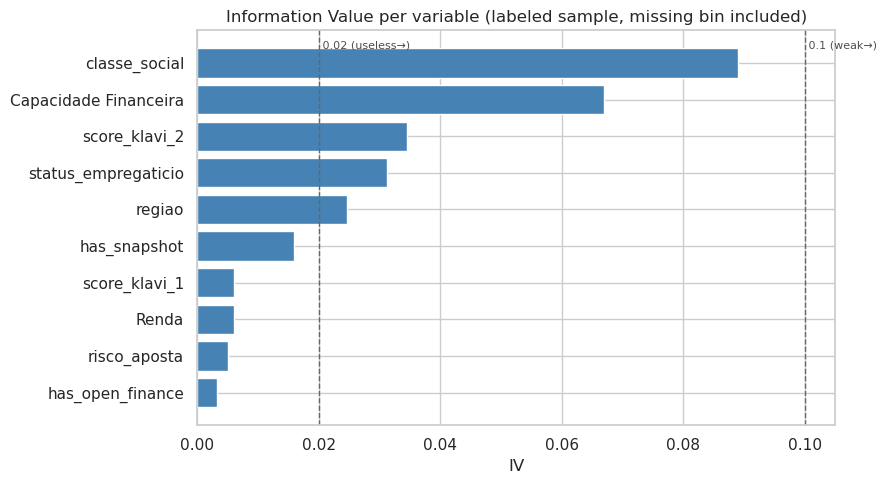

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
d = iv_summary.sort_values("IV")
ax.barh(d["variable"], d["IV"], color=COLOR_POS)
for thr, name in woe.IV_THRESHOLDS[:2]:                  # 0.3 / 0.5 lie far outside the data range
    ax.axvline(thr, color="0.4", lw=1, ls="--")
    ax.text(thr, len(d) - 0.4, f" {thr} ({name}→)", color="0.3", fontsize=8, va="top")
ax.set_title("Information Value per variable (labeled sample, missing bin included)")
ax.set_xlabel("IV")
plt.tight_layout()
save_fig(fig, "fig_iv_ranking.png", FIG_DIR)
plt.show()

**Key takeaway**: univariate signal is **modest across the board** — no variable reaches
"medium" (0.1): `classe_social` 0.089, `Capacidade Financeira` 0.067, `score_klavi_2` 0.034,
`status_empregaticio` 0.031, `regiao` 0.025. Nothing is remotely in leakage territory
(> 0.5). The open-finance trio scores near zero (IV ≤ 0.006) **because 95.5% missingness
dominates its distribution** — whatever signal exists in the covered 4.5% cannot carry a
pooled ranking. `has_snapshot` alone has IV 0.016: having no Klavi data is itself mildly
predictive. This tempers 1.0 §7's visual impression that categoricals were "strong"
predictors — separation exists, but it is weak-tier by IV standards.

**Variable selection**: the shortlist is the top-IV slice `classe_social` → `status_empregaticio`,
frozen in `credit_policy.VAR_SELECTION` (single source of truth for 2.0/2.1/2.2). `regiao` — next
by IV (0.025) — is **excluded on fairness grounds** (region proxies protected attributes →
redlining / disparate-impact risk; see `analysis-plan.md`). Kept as an explicit list so a re-run
with shifted IVs cannot silently change membership; the shortlist is validated in 2.2.

In [5]:
# Frozen shortlist, imported from the module (single source of truth); validated in 2.2.
# Everything below status_empregaticio is useless-tier / ~4.5% coverage; regiao dropped (fairness).
VAR_SELECTION

['classe_social',
 'Capacidade Financeira',
 'score_klavi_2',
 'status_empregaticio']

## 3. Next steps (Phase 2)

The per-bin WoE table, the WoE *shape* profiles and the WoE-over-SAFRA stability read all live in
**notebook 2.0 (binning workbench)** — that is where the bins in `references/bin_spec.yaml` get
hand-merged until each variable is stable across vintages *and* discriminating. Still pending for
Phase 2 (see `docs/analysis-plan.md` Fase 2): PSI / population stability & IV-per-vintage,
redundancy / correlation between the shortlisted candidates, a leakage screen, and a weighting
sensitivity check (one-row-per-`uuid`) for the re-applicant over-representation flagged in 1.2.